# Reproducing the paper's results

This notebook reproduces every table, figure, and headline statistic reported in
the paper, reading only the already-computed summary files committed under
`data/validation/` (the nine-architecture engine tournament) and `data/llm_validation/`
(the nine-language-model comparison) -- it does **not** re-run any simulation or call
any LLM. See `notebooks/validation_exhaustive.ipynb` and
`notebooks/analyze_llm_validation.ipynb` for the notebooks that actually produced these
summary files from the raw per-negotiation logs.

Part A reproduces Tables 1-2 and Figures 1-6 (the nine-architecture tournament).
Part B reproduces Tables 3-5 and Figures 7-8 (the language-model comparison).
Part C notes what is **not** in the paper (the RL2-vs-RL2Fixed ablation, the
hyperparameter sensitivity check) and a data-quality issue found and fixed while
preparing Part B, disclosed here for the same transparency reason it is disclosed in
the paper's §3.6 methods note.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT.parent))  # repo root: the wehaveadeal package

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

VALID_DIR = PROJECT_ROOT / "data" / "validation"
LLM_DIR = PROJECT_ROOT / "data" / "llm_validation"


def show_image(path, title=None, figsize=(11, 6)):
    img = mpimg.imread(path)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img)
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


## Part A -- The nine-architecture engine tournament

Nine negotiation architectures (R, RV, IS, OPT, OPT2, ML, ML2, RL, RL2), competing
simultaneously -- not in isolated duels -- under three market conditions: `balanced`
(all nine on both sides), `carrier_scarce` (carriers reduced to 7 of 9, rotated across
all 36 exclusion pairs), and `shipper_scarce` (the mirror condition). See the paper's
§2 (Methods) for the full protocol and §3 (Results) for the discussion below.


In [2]:
engine_summary = pd.read_csv(VALID_DIR / "summary_stats.csv")


def engine_table(role):
    sub = engine_summary[engine_summary.role == role].copy()
    pv = sub.pivot_table(index="arch", columns="config", values=["mean_outcome", "match_rate"])
    order = ["balanced", "carrier_scarce", "shipper_scarce"]
    pv = pv.reorder_levels([1, 0], axis=1)[[(c, m) for c in order for m in ("match_rate", "mean_outcome")]]
    return pv.sort_values(("balanced", "mean_outcome"), ascending=False).round(2)


print("Table 1 (paper): carrier-side match rate and mean margin, by architecture and market condition")
engine_table("carrier")


Table 1 (paper): carrier-side match rate and mean margin, by architecture and market condition


config   balanced              carrier_scarce              shipper_scarce             
       match_rate mean_outcome     match_rate mean_outcome     match_rate mean_outcome
arch                                                                                  
ML2           0.8         98.5            0.8        111.9            0.6         65.1
RL            0.6         90.4            0.8        141.9            0.2         40.8
OPT2          0.8         83.5            0.9        113.8            0.7         64.4
OPT           0.8         79.8            0.9         78.7            0.8         75.4
IS            0.7         71.4            0.8        115.2            0.2         30.6
ML            0.9         46.4            0.9         61.4            0.9         59.9
RL2           0.9         28.7            0.9         35.5            0.9         36.4
RV            0.9        -21.8            0.9          0.2            0.9        -40.4
R             0.9        -45.8            0.9        -18.5            0.9        -62.1

In [3]:
print("Table 2 (paper): shipper-side match rate and mean profit, by architecture and market condition")
engine_table("shipper")


Table 2 (paper): shipper-side match rate and mean profit, by architecture and market condition


config   balanced              carrier_scarce              shipper_scarce             
       match_rate mean_outcome     match_rate mean_outcome     match_rate mean_outcome
arch                                                                                  
RL            0.8      1,124.8            0.6        779.2            0.8      1,233.7
R             0.8      1,094.4            0.7        800.5            0.9      1,212.9
OPT           0.8      1,082.5            0.7        867.1            0.9      1,143.5
IS            0.8      1,068.9            0.7        833.1            0.8      1,149.7
RV            0.8      1,066.9            0.7        795.5            0.9      1,122.9
ML            0.8      1,063.9            0.7        891.6            0.9      1,109.8
OPT2          0.8      1,055.7            0.7        885.0            0.9      1,139.6
ML2           0.8      1,038.8            0.7        852.0            0.9      1,240.8
RL2           0.8        788.2            0.8        849.9            0.8        776.8

### Pairwise significance after Holm-Bonferroni correction (§3.2)

27/36, 28/36, and 30/36 carrier-side comparisons are significant across balanced,
carrier_scarce, and shipper_scarce respectively; 8/36, 0/36, and 8/36 on the shipper
side -- the complete absence of significant shipper-side differences under
`carrier_scarce` is itself a reported finding (§3.2).


In [4]:
pairwise = pd.read_csv(VALID_DIR / "pairwise_tests.csv")
sig_counts = pairwise.groupby(["config", "role"])["significant"].agg(["sum", "count"])
sig_counts.columns = ["significant", "total_comparisons"]
sig_counts


significant  total_comparisons
config         role                                   
balanced       carrier           27                 36
               shipper            8                 36
carrier_scarce carrier           28                 36
               shipper            0                 36
shipper_scarce carrier           30                 36
               shipper            8                 36

### Figures 1-2 (paper): ranking by condition and the shipper-balanced win matrix

The win matrix below is reproduced larger in the paper as Figure 2 specifically because
it is where RL2 loses every one of its eight comparisons (§3.2, §3.4) -- the
clearest single picture of the train/deployment gap discussed in §3.4.


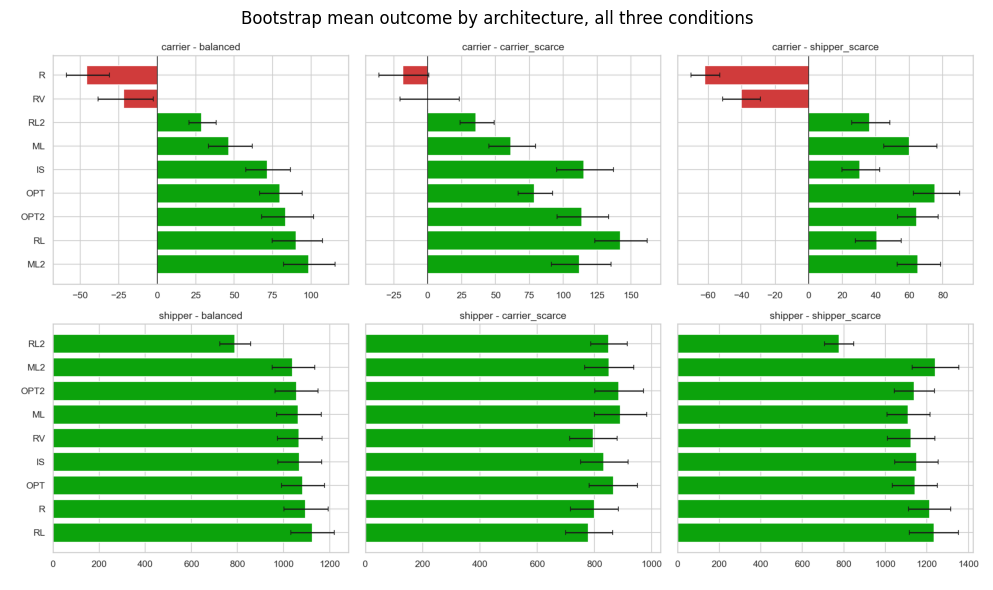

In [5]:
show_image(VALID_DIR / "ranking_by_config.png", "Bootstrap mean outcome by architecture, all three conditions")


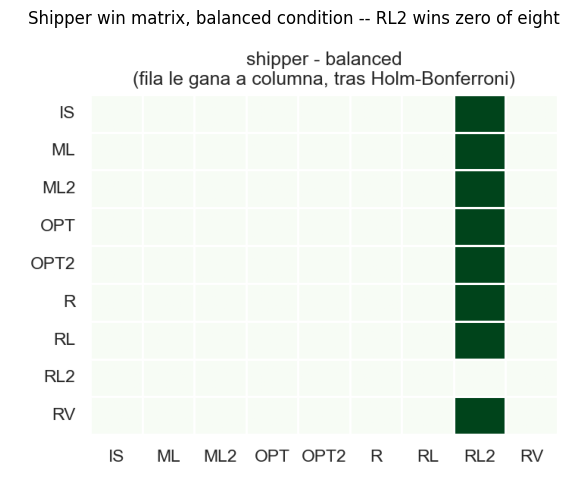

In [6]:
show_image(VALID_DIR / "win_matrix_shipper_balanced.png", "Shipper win matrix, balanced condition -- RL2 wins zero of eight", figsize=(6, 5))


### Headline findings (§3.3-§3.5)

- **Competitive collapse under scarcity**: RL's carrier-side match rate falls from 62%
  (balanced) to 84% (carrier_scarce, where carriers are *not* competing with each other)
  to **16%** under shipper_scarce, the one condition where carriers genuinely compete for
  scarce demand. IS falls similarly, 69% -> 82% -> **23%**. Neither architecture's
  training/search ever represented losing a deal to a rival carrier.
- **RL2 avoids that collapse** (match rate stays 92%/93%/92% across all three
  conditions) but is undone on realized payoff: every one of its eight shipper-side
  comparisons in the balanced condition is a significant loss ($p_{holm} < 10^{-12}$),
  traced to a confirmed train/deployment feature mismatch (the policy's own
  portfolio-occupancy feature was pinned at a neutral default throughout training).
- Table below: the eight RL2-vs-rival comparisons underlying that claim.


In [7]:
rl2_balanced = pairwise[
    (pairwise.config == "balanced")
    & ((pairwise.arch_a == "RL2") | (pairwise.arch_b == "RL2"))
]
rl2_balanced[["role", "arch_a", "arch_b", "mean_diff", "ci_lo", "ci_hi", "p_holm", "significant"]].sort_values(["role", "p_holm"])


,role,arch_a,arch_b,mean_diff,ci_lo,ci_hi,p_holm,significant
31,carrier,R,RL2,-74.5,-90.0,-57.6,0.0,True
35,carrier,RL2,RV,50.5,30.8,68.3,0.0,True
19,carrier,ML2,RL2,69.8,51.8,88.0,0.0,True
33,carrier,RL,RL2,61.7,44.7,79.4,0.0,True
24,carrier,OPT,RL2,51.1,35.1,67.3,0.0,True
28,carrier,OPT2,RL2,54.9,36.8,75.5,0.0,True
6,carrier,IS,RL2,42.7,26.5,60.6,0.0,True
13,carrier,ML,RL2,17.7,1.3,34.3,1.0,False
69,shipper,RL,RL2,336.6,280.1,394.0,0.0,True
67,shipper,R,RL2,306.2,248.5,362.4,0.0,True


---
## Part B -- Nine language models vs. the same engines

Nine language models (Llama, Qwen, and a DeepSeek-R1 distillation, at tiny <3B, small
4-14B, and medium 15-70B parameter tiers) embedded in the same tournament protocol
alongside three fixed same-side rivals (R, OPT2, ML2) and a fixed four-architecture
counterpart roster (R, RV, OPT2, IS), for 40 days per (model, role) combination. See
the paper's §3.6 for the two methodological notes (a seed-determinism bug found and
fixed, and an inconclusive `think=false` intervention) before trusting any number below.


In [8]:
llm_summary = pd.read_csv(LLM_DIR / "summary_stats.csv")

model_tier = (
    pd.concat([pd.read_json(p, lines=True) for p in LLM_DIR.glob("*_outcomes.jsonl")])
    [["model", "tier", "family"]]
    .drop_duplicates()
    .set_index("model")
)


def llm_table(role):
    sub = llm_summary[llm_summary.role == role].copy()
    sub["tier"] = sub["label"].map(model_tier["tier"]).fillna("rival")
    sub["family"] = sub["label"].map(model_tier["family"]).fillna("--")
    order = {"tiny": 0, "small": 1, "medium": 2, "rival": 3}
    sub = sub.sort_values(by=["tier", "mean_outcome"], key=lambda s: s.map(order) if s.name == "tier" else s, ascending=[True, False])
    return sub[["tier", "family", "label", "match_rate", "mean_outcome", "ci_lo", "ci_hi"]].round(2).set_index(["tier", "family", "label"])


print("Table 3 (paper): carrier-side LLM results, plus the three fixed rivals pooled across all nine markets")
llm_table("carrier")


Table 3 (paper): carrier-side LLM results, plus the three fixed rivals pooled across all nine markets


match_rate  mean_outcome  ci_lo  ci_hi
tier   family      label                                                   
tiny   llama       llama3.2:1b              0.4         -18.1  -33.2   -3.8
       qwen        qwen2.5:1.5b             0.8         -63.5  -88.1  -40.7
       deepseek-r1 deepseek-r1:1.5b         0.9         -64.6  -89.7  -39.0
small  deepseek-r1 deepseek-r1:7b           1.0         -87.7 -114.3  -60.0
       llama       llama3.1:8b              1.0        -113.0 -134.1  -90.7
       qwen        qwen2.5:7b               1.0        -136.0 -157.4 -112.5
medium llama       llama3.3:70b             0.8          25.4    5.6   43.2
       deepseek-r1 deepseek-r1:70b          0.0          -0.4   -1.3    0.0
       qwen        qwen2.5:72b              1.0         -20.9  -44.5    0.9
rival  --          ml2                      1.0          68.6   66.5   70.8
                   opt2                     1.0          63.9   61.5   66.2
                   r                        1.0         -60.9  -68.8  -53.2

In [9]:
print("Table 4 (paper): shipper-side LLM results")
llm_table("shipper")


Table 4 (paper): shipper-side LLM results


match_rate  mean_outcome   ci_lo   ci_hi
tier   family      label                                                     
tiny   qwen        qwen2.5:1.5b             1.0         462.5   294.4   652.3
       deepseek-r1 deepseek-r1:1.5b         0.9         379.8   224.6   559.0
       llama       llama3.2:1b              0.5           2.7     0.0     7.8
small  deepseek-r1 deepseek-r1:7b           1.0         584.9   418.3   756.8
       llama       llama3.1:8b              1.0         548.6   390.0   716.0
       qwen        qwen2.5:7b               0.6         406.9   228.9   610.6
medium llama       llama3.3:70b             1.0       1,264.1 1,073.5 1,454.0
       qwen        qwen2.5:72b              1.0         908.8   741.9 1,082.5
       deepseek-r1 deepseek-r1:70b          0.0           3.8     0.0    11.2
rival  --          r                        1.0       1,163.1 1,101.6 1,225.5
                   opt2                     1.0       1,148.8 1,082.2 1,210.8
                   ml2                      1.0       1,117.8 1,055.4 1,180.2

### Pairwise vs. the three fixed rivals, and the tier/family breakdown (§3.6)

54 total comparisons (9 models x 2 roles x 3 rivals): 42 significant losses, 4
significant wins (all against R, all on the carrier side), 8 inconclusive. Against
OPT2/ML2 combined: 32/36 significant losses, zero wins.


In [10]:
pairwise_llm = pd.read_csv(LLM_DIR / "pairwise_vs_rivals.csv")

summary_rows = []
for rival in ["r", "opt2", "ml2"]:
    sub = pairwise_llm[pairwise_llm.rival == rival]
    summary_rows.append({
        "rival": rival,
        "sig_loss": int(((sub.significant) & (sub.mean_diff < 0)).sum()),
        "sig_win": int(((sub.significant) & (sub.mean_diff > 0)).sum()),
        "inconclusive": int((~sub.significant).sum()),
        "total": len(sub),
    })
pd.DataFrame(summary_rows).set_index("rival")


,sig_loss,sig_win,inconclusive,total
rival,,,,
r,10,4,4,18
opt2,16,0,2,18
ml2,16,0,2,18


In [11]:
tier_summary = pd.read_csv(LLM_DIR / "tier_summary.csv")
print("Pooled by tier (language models only) -- note the carrier-side non-monotonicity (\u00a73.6)")
tier_summary.round(2)


Pooled by tier (language models only) -- note the carrier-side non-monotonicity (§3.6)


,role,tier,n,match_rate,mean_outcome,ci_lo,ci_hi
0,carrier,tiny,120,0.7,-48.7,-61.9,-36.3
1,carrier,small,111,1.0,-112.7,-126.4,-98.6
2,carrier,medium,120,0.6,1.4,-9.3,11.6
3,shipper,tiny,120,0.8,281.7,196.0,373.4
4,shipper,small,117,0.9,511.7,406.6,617.8
5,shipper,medium,119,0.7,721.0,596.5,848.6


### Figures 7-8 (paper): LLM vs. fixed rivals, and by tier/family

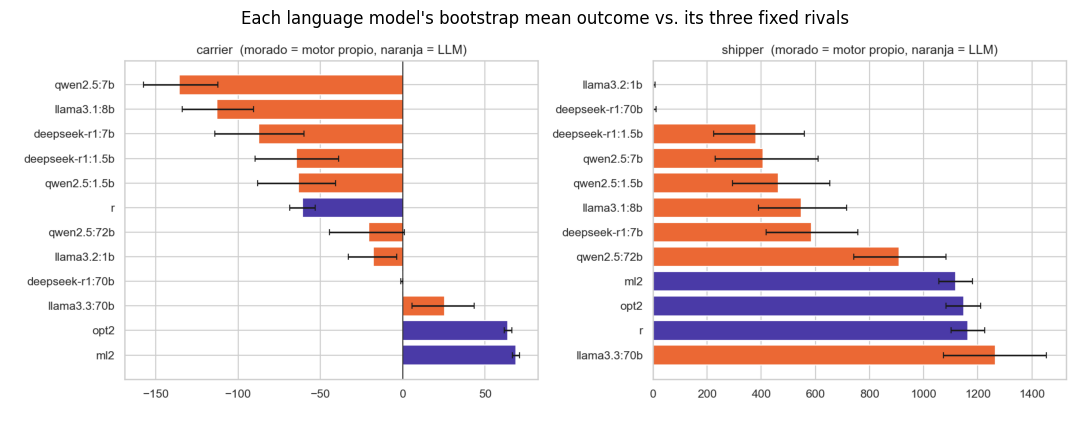

In [12]:
show_image(LLM_DIR / "llm_vs_engines.png", "Each language model's bootstrap mean outcome vs. its three fixed rivals")


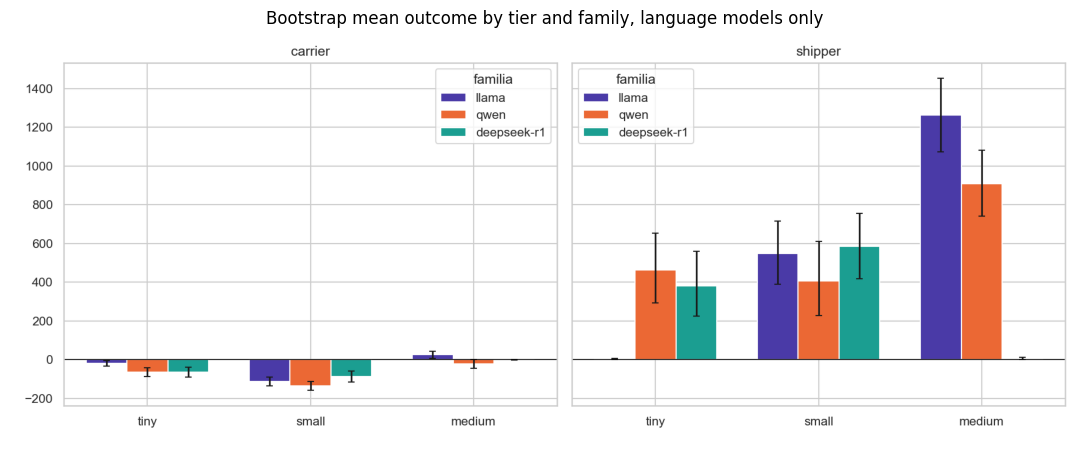

In [13]:
show_image(LLM_DIR / "llm_by_tier_family.png", "Bootstrap mean outcome by tier and family, language models only")


### The `deepseek-r1:70b` collapse, and why `think=false` didn't fix it

`deepseek-r1:70b` matches only **2.5%** of the time on both roles, against 90-100% for
every other model including its own 1.5B/7B siblings. The compliance/latency table
below is split by role specifically because DeepSeek-R1's `think` setting differs
between carrier (default reasoning) and shipper (`think=false`) -- and the comparison
shows the intervention did not help: latency is flat-to-slightly-worse with thinking
disabled, at every DeepSeek-R1 scale.


In [14]:
compliance = pd.read_csv(LLM_DIR / "compliance_by_role.csv")
compliance.pivot_table(index=["tier", "family", "model"], columns="role", values=["first_try_ok_rate", "mean_latency_s", "p95_latency_s"]).round(2)


first_try_ok_rate         mean_latency_s         p95_latency_s        
role                                          carrier shipper        carrier shipper       carrier shipper
tier   family      model                                                                                  
medium deepseek-r1 deepseek-r1:70b                0.2     0.3           91.6    92.0          92.1    92.1
       llama       llama3.3:70b                   0.7     1.0           29.3    30.2          37.8    38.1
       qwen        qwen2.5:72b                    0.8     0.9           41.6    31.0          66.6    38.0
small  deepseek-r1 deepseek-r1:7b                 0.6     0.9            9.0    10.6          15.0    22.9
       llama       llama3.1:8b                    0.9     0.9            2.6     2.5           2.7     2.6
       qwen        qwen2.5:7b                     0.6     0.8            2.4     2.4           2.5     2.6
tiny   deepseek-r1 deepseek-r1:1.5b               0.5     0.5           17.1    21.7          92.1    92.0
       llama       llama3.2:1b                    0.3     0.3            2.3     2.2           2.5     2.4
       qwen        qwen2.5:1.5b                   0.5     0.6            2.3     2.3           2.4     2.4

---
## Part C -- Not reported in the paper, and a data-quality note

**Supplementary, not reported in the paper**: the RL2-vs-RL2Fixed retraining ablation
(`data/validation/ablation_rl2fixed_raw_results.csv` has the raw results; no bootstrap
CI / pairwise analysis has been run on it) and the hyperparameter sensitivity check
discussed alongside it. Both are separate from the results reproduced above.

**Data-quality note**: while building
Part B, two of the eighteen `(model, role)` raw output files were found to have more
outcome rows than days -- traced to `run_llm_validation.py` deriving its per-combo seed
from Python's randomized `hash()`, which is not reproducible across the many process
restarts this unattended study required. Fixed with a deterministic hash
(`zlib.crc32`); the two affected files were deduplicated by hand (one day with a
genuinely unreconstructable mixed record was dropped entirely rather than guessed at);
the analysis above reads the *post-fix* data throughout. Same-day comparisons (every
number in Part B) are unaffected by this bug, since a model and its three rivals always
share one `run_round` call regardless of which seed produced that call.


---
## Part D -- Negotiation trajectories: what the LLMs actually said, turn by turn

Everything above is aggregate statistics. This section looks at individual negotiation
tables directly, built from `data/llm_validation/*_calls.jsonl` -- the raw log of every
model call, including its full JSON response and reasoning text. **No re-simulation and
no new model calls were made for this section**: every number and every quoted
`"reasoning"` string below is exactly what the model said during the actual data
collection.

One real limitation: `calls.jsonl` logs only the LLM's own responses, never its
counterpart's offers (those were visible to the model in its prompt but were never
persisted separately). So the charts below show the LLM's own half of each
negotiation -- what it offered and how that evolved -- not a two-sided price
convergence chart. `calls.jsonl` also has no `day_index` field, so a single table's
historical days are told apart by inferring where the turn/attempt sequence resets
(see `split_episodes()` below); each example is one specific historical day, not an
average.


In [15]:
import sys as _sys
_sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from _build_trajectory_figures import get_episode, parsed_amount, final_per_turn  # noqa: E402


### Two ordinary negotiations

Left: `llama3.1:8b` as carrier, conceding downward turn by turn (as the hard-band rule
requires) from \$2734 to \$2605 over five turns against IS. Right: `qwen2.5:72b` as
shipper, conceding upward from \$2800 to \$2975 against OPT2 over six turns -- and
still getting rejected at the end, a reminder that a reasonable-looking concession
path does not guarantee a deal.


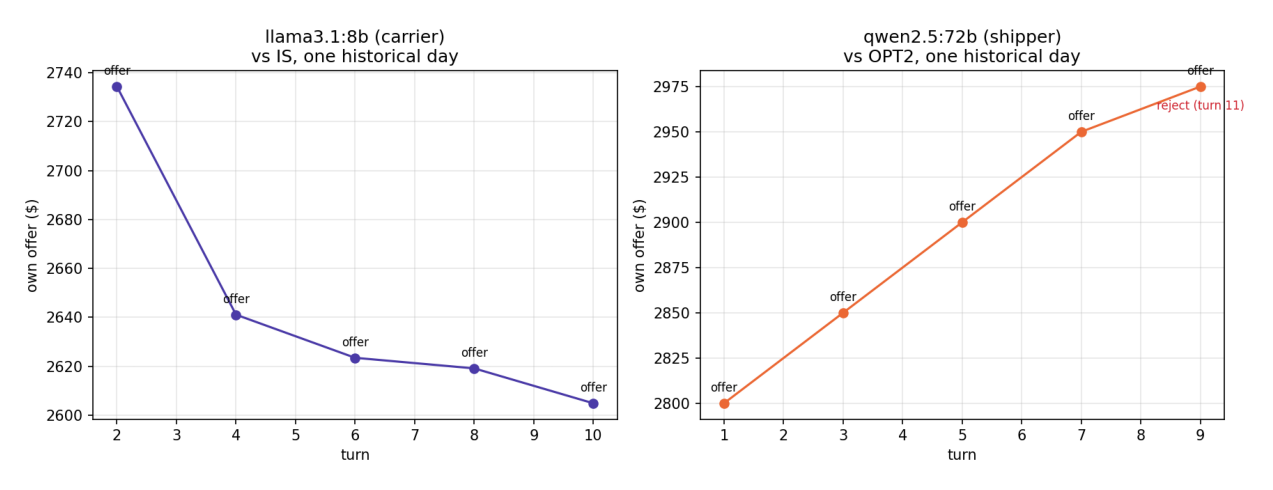

In [16]:
show_image(PROJECT_ROOT / "figures" / "llm_trajectory_clean_examples.png", figsize=(13, 5))


### The `deepseek-r1:70b` collapse, directly

Section 3.6's headline finding -- a 2.5% match rate driven by latency pinned at the
90-second ceiling -- shown directly rather than only as a summary statistic: the first
twelve logged attempts for one table all time out at ~92 seconds, in groups of three
(the `max_retries=2` retry budget) followed by a forfeit, repeating day after day.


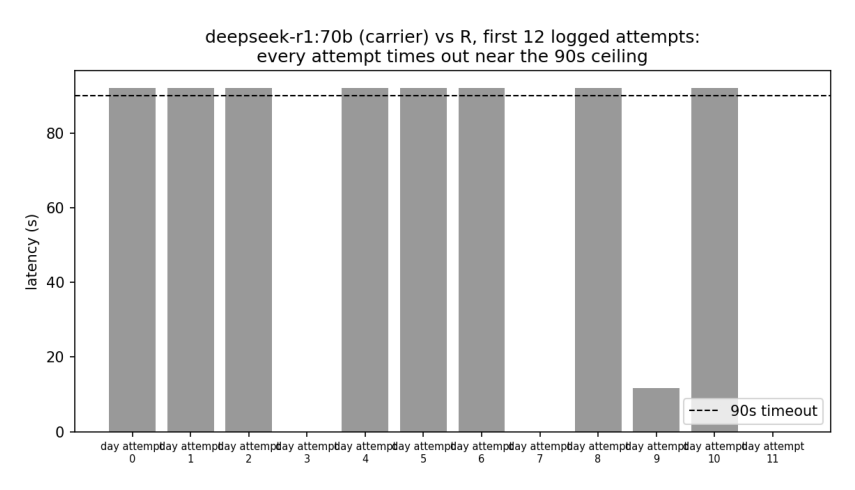

In [17]:
show_image(PROJECT_ROOT / "figures" / "llm_trajectory_timeout_example.png", figsize=(9, 5))


### A model confusing itself: repeated illegal "accept", `deepseek-r1:7b`

Not every failure is a format error or a timeout. In this historical day,
`deepseek-r1:7b` (shipper, vs. IS) repeatedly tries to **accept** a price that was not
actually legal to accept -- including inventing a non-null `amount` on an `"accept"`
action, even though the prompt's own schema states `amount` "must be null otherwise."
Three attempts at turn 9 all repeat the same illegal accept before the table forfeits.


In [18]:
ep = get_episode("deepseek-r1-7b_shipper_calls.jsonl", "shipper-llm-1::carrier-is-1", 13)
rows = []
for r in ep:
    action, amount = parsed_amount(r["raw_text"])
    rows.append({
        "turn": r["turn"], "attempt": r["attempt"],
        "action": action, "amount": amount,
        "note": "FORFEIT (exhausted retries)" if r["attempt"] == "forfeit" else "",
    })
pd.DataFrame(rows)


,turn,attempt,action,amount,note
0,1,0,offer,"3,000.0",
1,3,0,accept,"3,000.0",
2,3,1,accept,"3,000.0",
3,3,2,offer,"3,000.0",
4,5,0,offer,"3,000.0",
5,7,0,accept,NaN,
6,7,1,offer,"3,000.0",
7,9,0,accept,"3,022.2",
8,9,1,accept,"3,022.2",
9,9,2,accept,"3,022.2",
